In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
# Load the monthly AirPassengers dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

In [ ]:
# Convert Month to datetime
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")


In [ ]:
# Set monthly frequency and extract passenger series
series = df["Passengers"].asfreq("MS").astype(float)

In [ ]:
# Display dataset details
print(df.head())
print("Total observations:", len(series))
print("Start date:", series.index.min())
print("End date:", series.index.max())

            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
Total observations: 144
Start date: 1949-01-01 00:00:00
End date: 1960-12-01 00:00:00


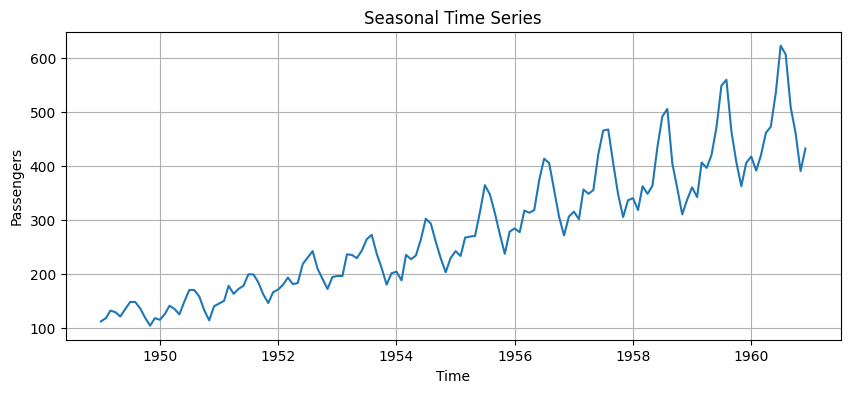

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(series)

plt.title("Seasonal Time Series")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.grid()
plt.show()

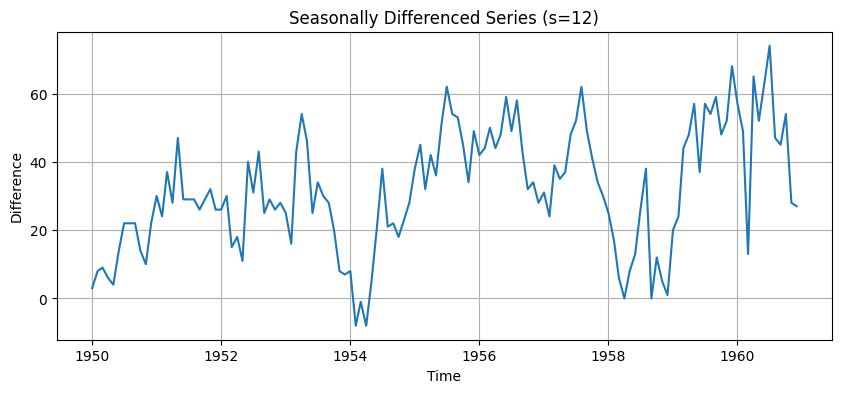

In [ ]:
# Seasonal differencing with s = 12
seasonal_diff = series.diff(12).dropna()

plt.figure(figsize=(10, 4))

plt.plot(seasonal_diff)

plt.title("Seasonally Differenced Series (s=12)")
plt.xlabel("Time")
plt.ylabel("Difference")
plt.grid()
plt.show()

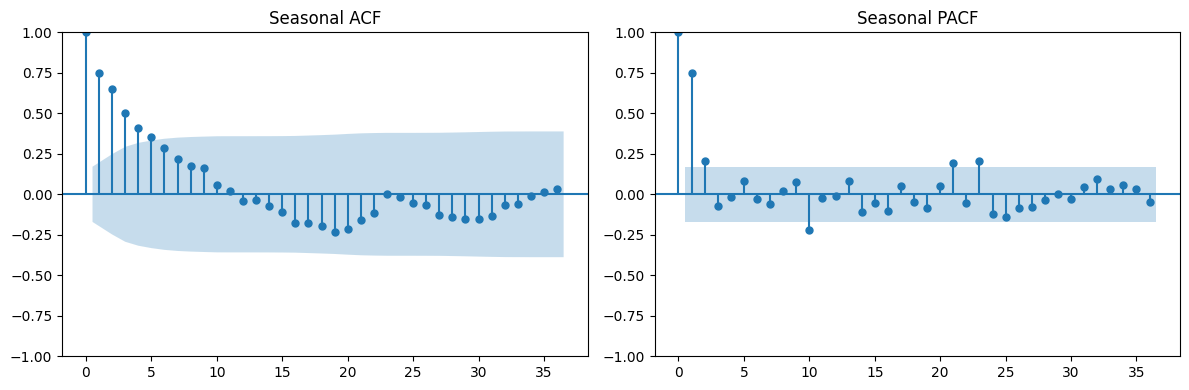

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(seasonal_diff, ax=axes[0], lags=36)
plot_pacf(seasonal_diff, ax=axes[1], lags=36, method="ywm")

axes[0].set_title("Seasonal ACF")
axes[1].set_title("Seasonal PACF")

plt.tight_layout()
plt.show()

In [ ]:
#The ACF plot shows a gradual decrease in autocorrelation across several lags, indicating that some temporal dependence remains in the seasonally differenced series.
The PACF plot shows a strong spike at lag 1 and smaller spikes at other lags.
These plots help identify candidate non-seasonal and seasonal AR and MA parameters.
The seasonal period is set to 12 because the dataset contains monthly observations with an annual pattern.
The ACF and PACF plots are used as guides for selecting the SARIMA model orders.

In [ ]:
# Train-test split
train_size = int(len(series) * 0.80)

train = series.iloc[:train_size]
test = series.iloc[train_size:]

print("Total observations:", len(series))
print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Total observations: 144
Training observations: 115
Testing observations: 29
Training period: 1949-01-01 00:00:00 to 1958-07-01 00:00:00
Testing period: 1958-08-01 00:00:00 to 1960-12-01 00:00:00


In [ ]:
# Fit SARIMA model
model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit = model.fit(disp=False)

# Display model summary
print(model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Thu, 29 Oct 2026   AIC                            657.601
Time:                                    17:24:09   BIC                            669.988
Sample:                                01-01-1949   HQIC                           662.592
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0.184     -4.461      0.000      -1.184      -0.461
ma.L1          0.7176      0.224   

In [ ]:
# Forecast the test period
forecast = model_fit.forecast(steps=len(test))

# Calculate evaluation metrics
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

MAE: 25.268
RMSE: 31.787


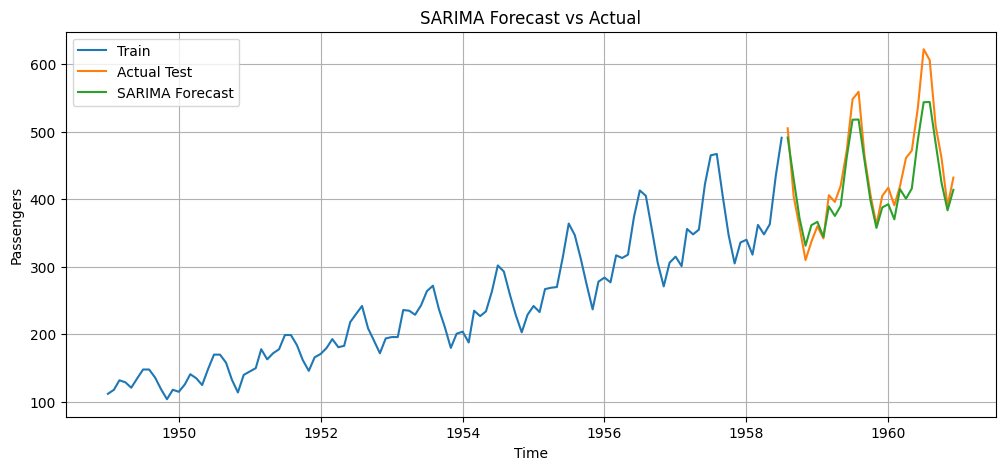

In [ ]:
# Plot actual values and SARIMA forecasts

plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Actual Test")
plt.plot(test.index, forecast, label="SARIMA Forecast")

plt.title("SARIMA Forecast vs Actual")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

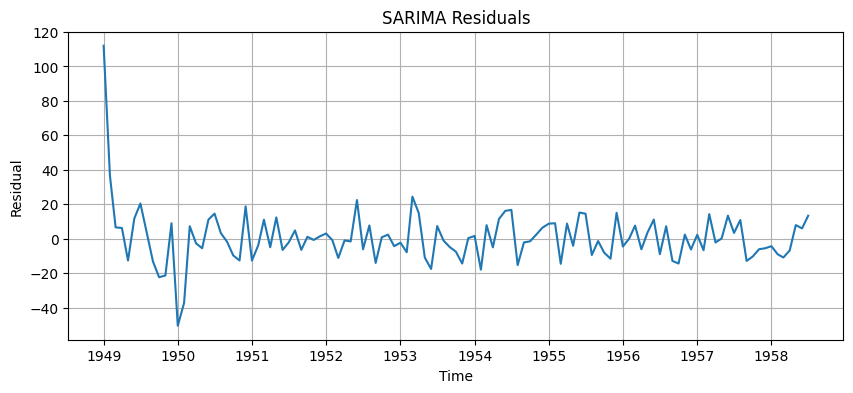

In [ ]:
# Extract residuals
residuals = model_fit.resid

# Plot residuals
plt.figure(figsize=(10, 4))
plt.plot(residuals)

plt.title("SARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid()
plt.show()

In [ ]:
#Independent Task 5.1 — Compare SARIMA models
# Task 5.1: Compare SARIMA configurations

configs = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((0, 1, 1), (0, 1, 1, 12)),
    ((2, 1, 1), (1, 1, 1, 12))
]

results = []

for order, seasonal_order in configs:

    model = SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    model_fit = model.fit(disp=False)
    forecast = model_fit.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results.append({
        "Order": str(order),
        "Seasonal Order": str(seasonal_order),
        "AIC": round(model_fit.aic, 3),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3)
    })

results_df = pd.DataFrame(results)
print(results_df)

       Order Seasonal Order      AIC     MAE    RMSE
0  (1, 1, 1)  (1, 1, 1, 12)  657.601  25.268  31.787
1  (0, 1, 1)  (0, 1, 1, 12)  659.342  24.059  30.580
2  (2, 1, 1)  (1, 1, 1, 12)  659.252  26.496  32.989


In [ ]:
#Task 5.2 — Explain the seasonal period
The seasonal period s=12 is appropriate for monthly data with annual seasonality because there are 12 months in one year.
A seasonal period of s=7 is suitable for daily data with a weekly pattern, as the observations repeat every seven days.
A seasonal period of s=24 is suitable for hourly data with a daily pattern because there are 24 hours in one day.
Selecting the correct seasonal period helps the SARIMA model capture recurring patterns in the time series.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

In [ ]:
#Task 5.3 — Compare ARIMA vs SARIMA
# Task 5.3: Compare ARIMA vs SARIMA

# Best ARIMA model from Task 4.1
arima_model = ARIMA(train, order=(2, 1, 1)).fit()
arima_forecast = arima_model.forecast(steps=len(test))

arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))

# SARIMA model from the main Lab 5 experiment
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.forecast(steps=len(test))

sarima_mae = mean_absolute_error(test, sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(test, sarima_forecast))

comparison = pd.DataFrame({
    "Model": ["ARIMA(2,1,1)", "SARIMA(1,1,1)(1,1,1,12)"],
    "MAE": [round(arima_mae, 3), round(sarima_mae, 3)],
    "RMSE": [round(arima_rmse, 3), round(sarima_rmse, 3)]
})

print(comparison)

                     Model     MAE    RMSE
0             ARIMA(2,1,1)  60.529  82.621
1  SARIMA(1,1,1)(1,1,1,12)  25.268  31.787


In [ ]:
#Task 5.4 — Seasonal differencing (D = 0 vs D = 1)
# Task 5.4: Effect of seasonal differencing

seasonal_orders = [
    (1, 0, 1, 12),  # D = 0
    (1, 1, 1, 12)   # D = 1
]

results_D = []

for seasonal_order in seasonal_orders:

    model = SARIMAX(
        train,
        order=(1, 1, 1),
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    model_fit = model.fit(disp=False)
    forecast = model_fit.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results_D.append({
        "Seasonal Order": str(seasonal_order),
        "AIC": round(model_fit.aic, 3),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3)
    })

results_D_df = pd.DataFrame(results_D)
print(results_D_df)

  Seasonal Order      AIC     MAE    RMSE
0  (1, 0, 1, 12)  721.684  18.697  22.399
1  (1, 1, 1, 12)  657.601  25.268  31.787
